# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

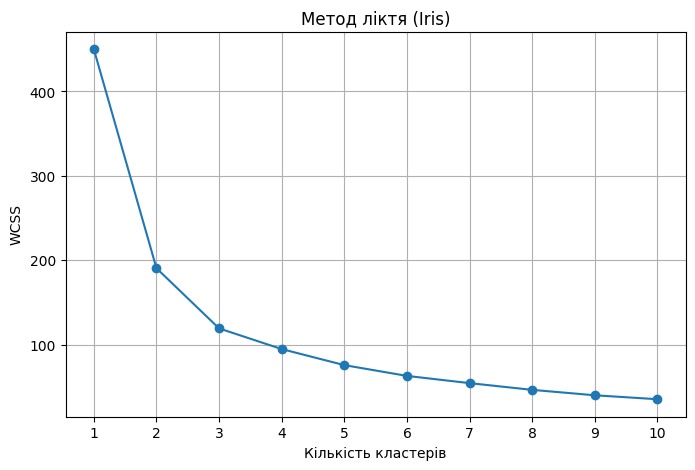

In [3]:
X_iris = df_iris.iloc[:, :3]
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_iris_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Метод ліктя (Iris)')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

k = 2: 0.5525
k = 3: 0.4594
k = 4: 0.4057
k = 5: 0.3755
k = 6: 0.3772
k = 7: 0.3628
k = 8: 0.3814
k = 9: 0.3749
k = 10: 0.3791


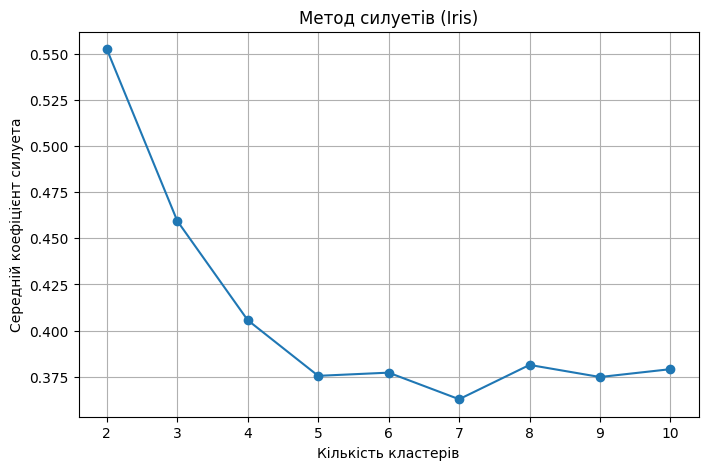

In [4]:
silhouette_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_iris_scaled)
    silhouette_scores.append(silhouette_score(X_iris_scaled, labels))

for k, s in zip(range(2, 11), silhouette_scores):
    print(f'k = {k}: {s:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Метод силуетів (Iris)')
plt.xlabel('Кількість кластерів')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

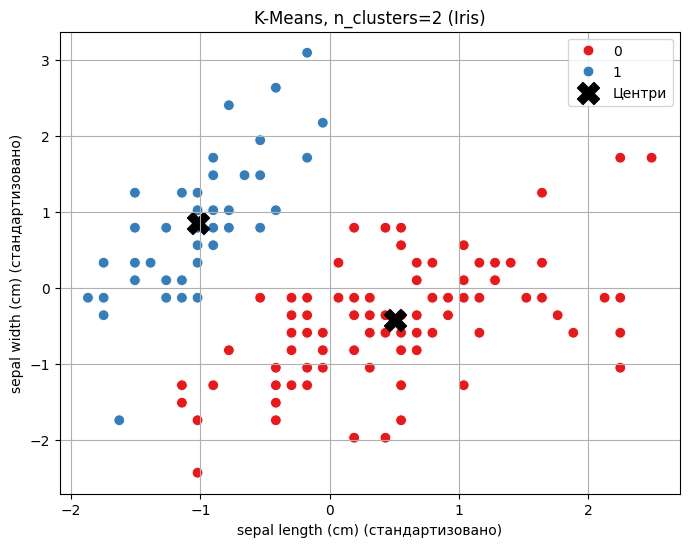

Координати центрів (перші дві ознаки):
[[ 0.50728948 -0.42663134]
 [-1.01457897  0.85326268]]


In [5]:
kmeans_iris = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_labels = kmeans_iris.fit_predict(X_iris_scaled)
centers = kmeans_iris.cluster_centers_

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_iris_scaled[:, 0], y=X_iris_scaled[:, 1], hue=iris_labels, palette='Set1', s=60)
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=250, label='Центри')
plt.title('K-Means, n_clusters=2 (Iris)')
plt.xlabel(X_iris.columns[0] + ' (стандартизовано)')
plt.ylabel(X_iris.columns[1] + ' (стандартизовано)')
plt.legend()
plt.grid(True)
plt.show()

print('Координати центрів (перші дві ознаки):')
print(centers[:, :2])

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Висновок до завдання 1.** Метод ліктя показує найбільше зменшення WCSS при переході від 1 до 2 кластерів (приблизно з 450 до 190), після чого спад суттєво сповільнюється. Метод силуетів дає найвищий середній коефіцієнт при k = 2 (0.5525), а при k = 3 він знижується до 0.4594 і далі тільки зменшується. Тому обрано 2 кластери, і цей вибір збігається з обома графіками. Хоча в Iris три види, setosa добре відокремлюється, а versicolor і virginica за трьома ознаками перекриваються, тому геометрично дані найкраще поділяються саме на дві групи.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)

(1913, 13) (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
rf_test_acc = accuracy_score(y_test, rf_grid.predict(X_test_scaled))

print('Найкращі параметри:', rf_grid.best_params_)
print(f'Середня CV-точність: {rf_grid.best_score_:.4f}')
print(f'Тестова accuracy: {rf_test_acc:.4f}')

Найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['saga']
}

lr_grid = GridSearchCV(LogisticRegression(max_iter=5000, random_state=42), lr_params, cv=5, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)
lr_test_acc = accuracy_score(y_test, lr_grid.predict(X_test_scaled))

print('Найкращі параметри:', lr_grid.best_params_)
print(f'Середня CV-точність: {lr_grid.best_score_:.4f}')
print(f'Тестова accuracy: {lr_test_acc:.4f}')

Найкращі параметри: {'C': 100, 'solver': 'saga'}
Середня CV-точність: 0.7977
Тестова accuracy: 0.7912


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(SVC(random_state=42), svm_params, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
svm_test_acc = accuracy_score(y_test, svm_grid.predict(X_test_scaled))

print('Найкращі параметри:', svm_grid.best_params_)
print(f'Середня CV-точність: {svm_grid.best_score_:.4f}')
print(f'Тестова accuracy: {svm_test_acc:.4f}')

Найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

,Модель,CV-точність,Тестова accuracy
0,Random Forest,0.921071,0.910230
1,Logistic Regression,0.797695,0.791232
2,SVM,0.852065,0.858038


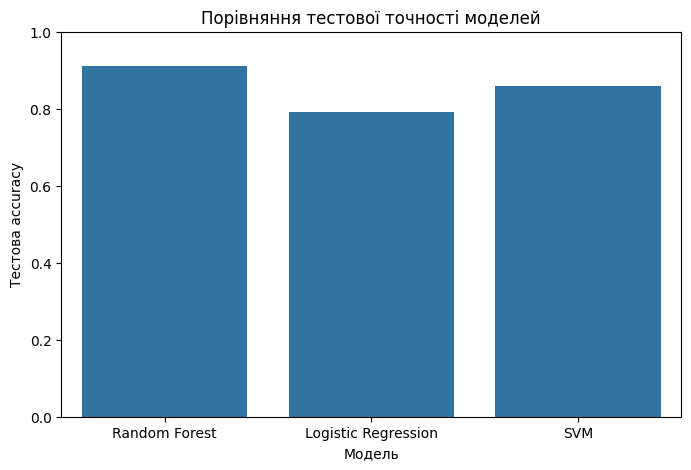

Найкраща модель за CV-точністю: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



In [18]:
grids = {
    'Random Forest': rf_grid,
    'Logistic Regression': lr_grid,
    'SVM': svm_grid
}

results = pd.DataFrame({
    'Модель': list(grids.keys()),
    'CV-точність': [g.best_score_ for g in grids.values()],
    'Тестова accuracy': [rf_test_acc, lr_test_acc, svm_test_acc]
})
display(results)

plt.figure(figsize=(8, 5))
sns.barplot(data=results, x='Модель', y='Тестова accuracy')
plt.title('Порівняння тестової точності моделей')
plt.ylim(0, 1)
plt.show()

best_name = results.loc[results['CV-точність'].idxmax(), 'Модель']
best_model = grids[best_name].best_estimator_
print('Найкраща модель за CV-точністю:', best_name)
print(classification_report(y_test, best_model.predict(X_test_scaled)))

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

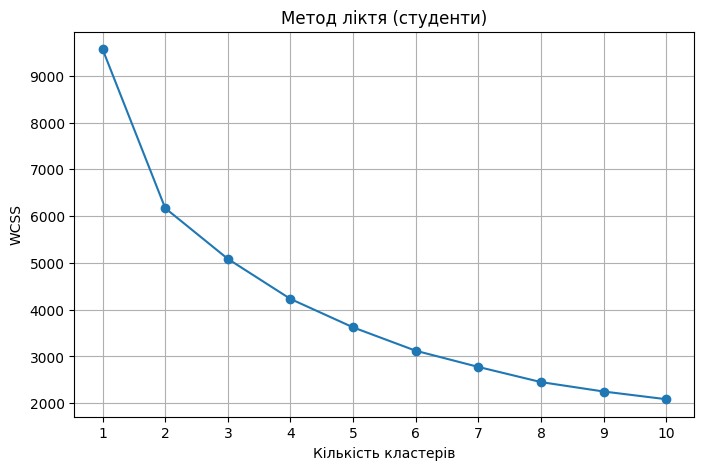

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students = StandardScaler().fit_transform(df[cluster_features])

wcss_students = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_students)
    wcss_students.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_students, marker='o')
plt.title('Метод ліктя (студенти)')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

k = 2: 0.3080
k = 3: 0.2702
k = 4: 0.2580
k = 5: 0.2645
k = 6: 0.2689
k = 7: 0.2692
k = 8: 0.2712
k = 9: 0.2732
k = 10: 0.2725


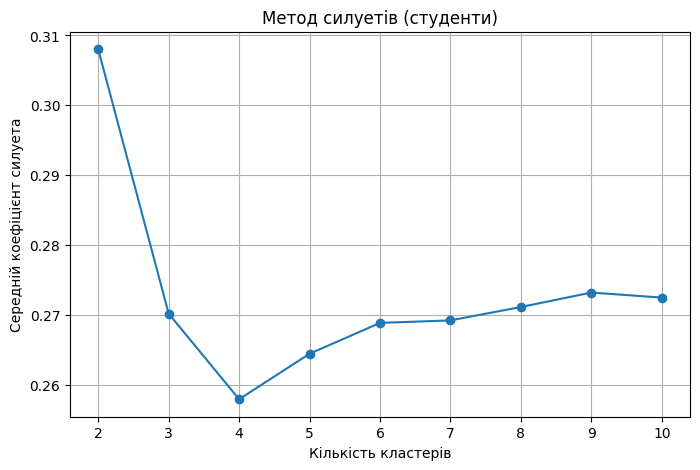

In [20]:
silhouette_students = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_students)
    silhouette_students.append(silhouette_score(X_students, labels))

for k, s in zip(range(2, 11), silhouette_students):
    print(f'k = {k}: {s:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_students, marker='o')
plt.title('Метод силуетів (студенти)')
plt.xlabel('Кількість кластерів')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])
X_all.head()

,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196
1,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915
2,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602
3,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218
4,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
X_all_scaled = StandardScaler().fit_transform(X_all)

pca = PCA()
pca.fit(X_all_scaled)
explained_variance = pca.explained_variance_ratio_

for i, v in enumerate(explained_variance, start=1):
    print(f'PC{i}: {v:.4f}')

PC1: 0.1525
PC2: 0.0861
PC3: 0.0827
PC4: 0.0807
PC5: 0.0786
PC6: 0.0779
PC7: 0.0763
PC8: 0.0760
PC9: 0.0744
PC10: 0.0738
PC11: 0.0717
PC12: 0.0675
PC13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

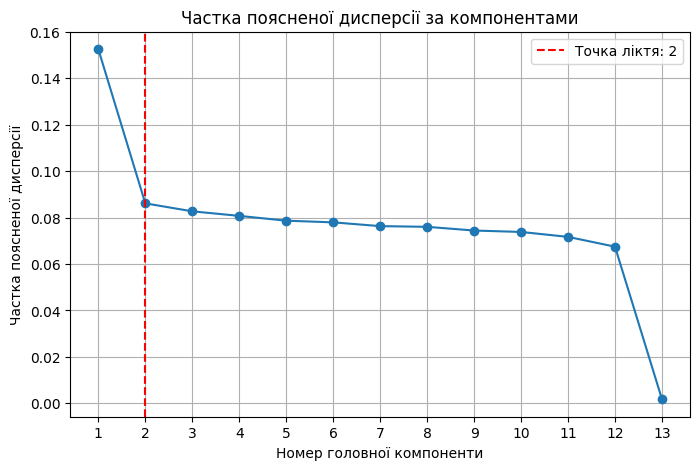

Обрана кількість компонент: 2


In [25]:
components = np.arange(1, len(explained_variance) + 1)
knee = KneeLocator(components, explained_variance, curve='convex', direction='decreasing')
n_components = int(knee.knee)

plt.figure(figsize=(8, 5))
plt.plot(components, explained_variance, marker='o')
plt.axvline(n_components, color='r', linestyle='--', label=f'Точка ліктя: {n_components}')
plt.title('Частка поясненої дисперсії за компонентами')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

print('Обрана кількість компонент:', n_components)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

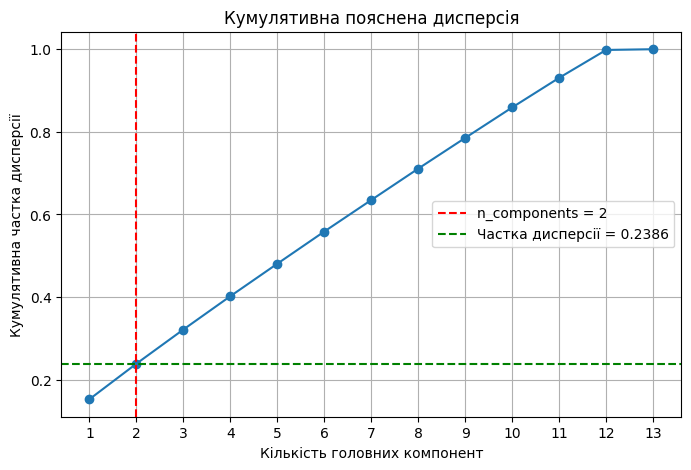

Частка дисперсії, яку пояснюють 2 компонент(и): 0.2386
Розмірність після PCA: (2392, 2)


In [26]:
cumulative_variance = np.cumsum(explained_variance)
selected_variance = cumulative_variance[n_components - 1]

plt.figure(figsize=(8, 5))
plt.plot(components, cumulative_variance, marker='o')
plt.axvline(n_components, color='r', linestyle='--', label=f'n_components = {n_components}')
plt.axhline(selected_variance, color='g', linestyle='--', label=f'Частка дисперсії = {selected_variance:.4f}')
plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

print(f'Частка дисперсії, яку пояснюють {n_components} компонент(и): {selected_variance:.4f}')

pca_final = PCA(n_components=n_components)
X_pca = pca_final.fit_transform(X_all_scaled)
print('Розмірність після PCA:', X_pca.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

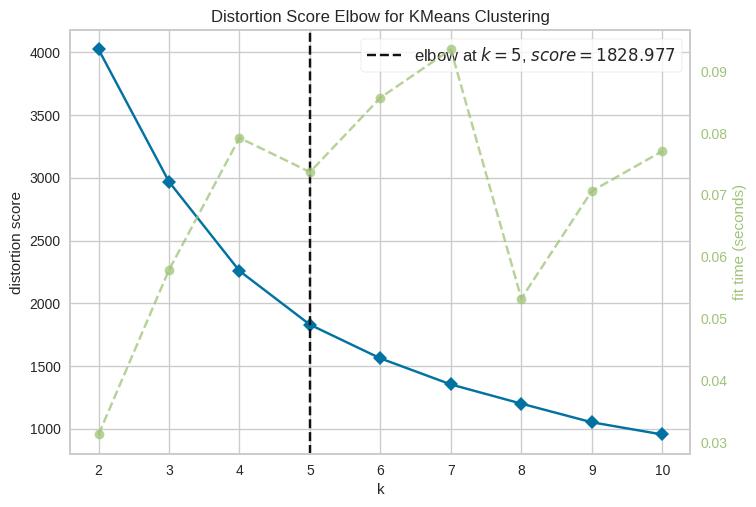

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [28]:
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(2, 11))
visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

**Висновки**

**Завдання 1 (Iris).** Метод ліктя показує найрізкіше зменшення WCSS при переході від 1 до 2 кластерів, далі спад сповільнюється (слабший злам ще на k = 3). Метод силуетів дає максимум при k = 2 (0.5525), при k = 3 значення вже нижче (0.4594). Обидва методи узгоджено вказують на 2 кластери: вид setosa чітко відокремлений, а versicolor і virginica за цими ознаками сильно перекриваються і K-Means об'єднує їх в один кластер.

**Завдання 2 (класифікація).** Найкращі результати показав Random Forest: CV-точність 0.9211, тестова accuracy 0.9102. SVM (лінійне ядро, C = 10) — 0.8521 / 0.8580, Logistic Regression (saga, C = 100) — 0.7977 / 0.7912. За CV-точністю обрано Random Forest. Найгірше розпізнається клас 0 (recall 0.29) через малу кількість прикладів (21 у тестовій вибірці).

**Завдання 2 (кластеризація за Age, StudyTimeWeekly, Absences, GPA).** Графік WCSS не має чіткого ліктя: найбільший спад між k = 1 і k = 2, далі крива спадає поступово. Коефіцієнт силуета максимальний при k = 2 (0.3080), але всі значення низькі (0.26–0.31), тобто кластерна структура слабка. Обидва методи вказують на 2 кластери.

**PCA.** Для всіх ознак, крім StudentID і GradeClass, KneeLocator визначив 2 головні компоненти. Вони пояснюють лише 0.2386 загальної дисперсії, оскільки дисперсія розподілена майже рівномірно між компонентами (приблизно 0.07–0.09 на кожну, крім першої — 0.1525), а ознаки слабко корельовані. Остання компонента пояснює лише 0.0018, що свідчить про майже лінійну залежність однієї з ознак від інших.

**Метод ліктя після PCA.** KElbowVisualizer на даних після PCA визначив k = 5 (distortion score = 1828.977). Це відрізняється від результату для чотирьох ознак (k = 2), бо використано інший набір ознак і автоматичний пошук ліктя на плавній кривій без явного зламу. Різні способи дають різну кількість кластерів, що також підтверджує відсутність чіткої кластерної структури в даних студентів.

**Класифікація vs кластеризація.** Класифікація — навчання з учителем: моделі навчаються на відомих мітках GradeClass і оцінюються за accuracy на тестових даних. Кластеризація — навчання без учителя: цільова змінна не використовується, K-Means групує студентів лише за схожістю ознак, тому отримані кластери не обов'язково відповідають класам GradeClass, а їх кількість визначається методами ліктя та силуетів.